# Projet 1 — Gradient et gradient stochastique pour la régression logistique

1. Adaptation au modèle logistique de [EE 227C, Lecture 4](https://ee227c.github.io/code/lecture4.html#Least-Squares)
   (*Least Squares* → régularisation $\ell_2$ ; le LASSO fait l'objet du projet 2).
2. Influence de la longueur du pas et de la taille du mini-batch.
3. Reproduction, avec notre optimiseur, des 6 vérifications d'hypothèses du notebook de
   [Kenneth Leung](https://github.com/kennethleungty/Logistic-Regression-Assumptions) sur **Titanic**, puis sur un
   jeu irlandais (**Irish Educational Transitions**).

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
np.random.seed(1337); rng = np.random.default_rng(1337)

def save(name):  # figures pour le rapport LaTeX
    if os.path.isdir('Rapport/Figures'): plt.savefig(f'Rapport/Figures/{name}.png', dpi=150, bbox_inches='tight')

## 1. Méthodes de gradient (adaptées de Berkeley)

Données $A\in\mathbb R^{m\times n}$ (lignes $a_i^\top$), $y\in\{0,1\}^m$, modèle $P(y_i=1)=\sigma(a_i^\top x)$,
$\sigma(t)=1/(1+e^{-t})$. On minimise la log-vraisemblance négative moyenne

$$f(x)=\frac1m\sum_{i=1}^m\big[\log(1+e^{a_i^\top x})-y_i a_i^\top x\big],\qquad
\nabla f(x)=\frac1mA^\top(\sigma(Ax)-y),\qquad \nabla^2f(x)=\frac1mA^\top W A,$$

avec $W=\mathrm{diag}(p_i(1-p_i))$. $f$ est convexe et $\beta$-lisse avec $\beta=\lambda_{\max}(A^\top A)/(4m)$
(car $p(1-p)\le 1/4$) ; elle n'est pas fortement convexe globalement. Pas théorique : $\eta=1/\beta$.

SGD par mini-batch : $x_{k+1}=x_k-\eta\,\frac1b\sum_{i\in B_k}\nabla f_i(x_k)$, estimateur sans biais de $\nabla f$.

In [2]:
def sigmoid(z):
    return np.exp(-np.logaddexp(0., -z))

def logistic(A, y, x, alpha=0.):
    z = A @ x
    return np.mean(np.logaddexp(0., z) - y * z) + alpha / 2 * x @ x

def logistic_gradient(A, y, x, alpha=0.):
    return A.T @ (sigmoid(A @ x) - y) / len(y) + alpha * x

def smoothness(A):
    return np.linalg.norm(A, 2) ** 2 / (4 * len(A))

def gradient_descent(init, steps, grad, proj=lambda x: x):
    # identique à Berkeley
    xs = [init]
    for step in steps:
        xs.append(proj(xs[-1] - step * grad(xs[-1])))
    return xs

def sgd(A, y, x0, step, batch_size, epochs, seed=0):
    # Gradient stochastique par mini-batch ; renvoie l'itéré à la fin de chaque epoch.
    gen = np.random.default_rng(seed); m = len(y); x = x0.copy(); xs = [x.copy()]
    for _ in range(epochs):
        perm = gen.permutation(m)
        for s in range(0, m, batch_size):
            i = perm[s:s + batch_size]
            x = x - step * logistic_gradient(A[i], y[i], x)
        xs.append(x.copy())
    return xs

def error_plot(ys, ax, label=None, yscale='log'):
    ax.plot(range(len(ys)), ys, label=label, lw=2); ax.set_yscale(yscale); ax.set_xlabel('Itération')

### 1.1 Cas surdéterminé $m\ge n$
Données simulées $y_i\sim\mathcal B(\sigma(a_i^\top x_{\rm vrai}))$. La solution « optimale » $x^\star$ est obtenue en
faisant tourner GD très longtemps.

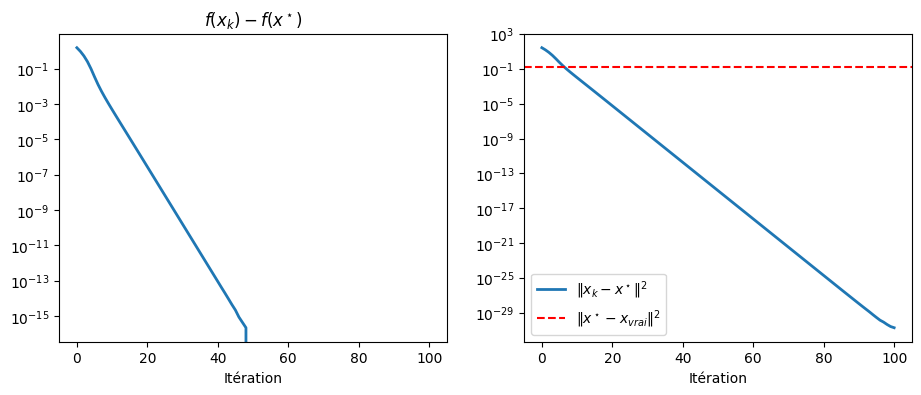

In [3]:
m, n = 1000, 20
A = rng.normal(0, 1, (m, n)); x_true = rng.normal(0, 1, n) / np.sqrt(n)
y = (rng.random(m) < sigmoid(A @ x_true)).astype(float)
objective = lambda x: logistic(A, y, x); gradient = lambda x: logistic_gradient(A, y, x)
beta = smoothness(A)
x_opt = gradient_descent(np.zeros(n), [1 / beta] * 3000, gradient)[-1]

x0 = rng.normal(0, 1, n)
xs = gradient_descent(x0, [1 / beta] * 100, gradient)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
error_plot([objective(x) - objective(x_opt) for x in xs], ax[0]); ax[0].set_title('$f(x_k)-f(x^\\star)$')
error_plot([np.linalg.norm(x - x_opt) ** 2 for x in xs], ax[1], label='$\\|x_k-x^\\star\\|^2$')
ax[1].axhline(np.linalg.norm(x_opt - x_true) ** 2, color='r', ls='--', label='$\\|x^\\star-x_{vrai}\\|^2$')
ax[1].legend(); save('berkeley_surdetermine'); plt.show()

Convergence linéaire en objectif et dans le domaine : $f$ est fortement convexe **au voisinage** de $x^\star$.
L'écart à $x_{\rm vrai}$ (erreur statistique) ne peut pas être réduit par l'optimisation.

### 1.2 Cas sous-déterminé $m<n$ et régularisation $\ell_2$
Avec $m<n$ les classes sont séparables : $f(tw)\to0$ quand $t\to\infty$, **il n'y a pas de minimiseur** et
$\|x_k\|\to\infty$ (lentement). La pénalité $\frac\alpha2\|x\|^2$ rend l'objectif $\alpha$-fortement convexe :
minimiseur unique et convergence linéaire dans le domaine.

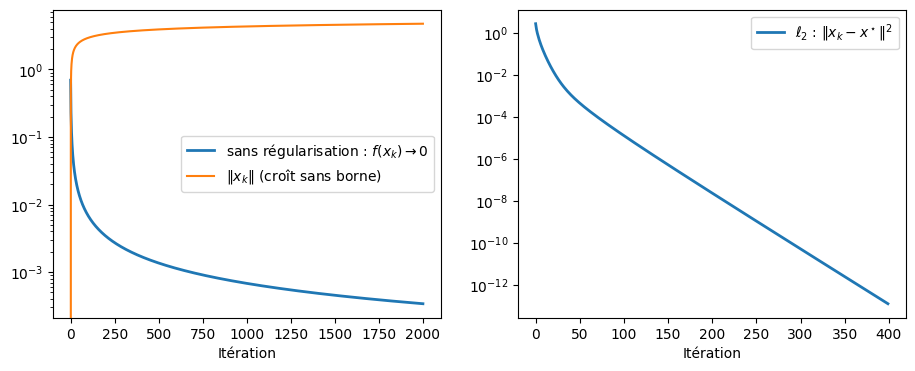

In [4]:
m, n = 100, 300
A = rng.normal(0, 1, (m, n)); y = (rng.random(m) < sigmoid(A @ rng.normal(0, 1, n) / np.sqrt(n) * 3)).astype(float)
beta = smoothness(A)
xs = gradient_descent(np.zeros(n), [1 / beta] * 2000, lambda x: logistic_gradient(A, y, x))
alpha = 0.05
xs_l2 = gradient_descent(np.zeros(n), [1 / (beta + alpha)] * 2000, lambda x: logistic_gradient(A, y, x, alpha))
x_l2 = xs_l2[-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
error_plot([logistic(A, y, x) for x in xs], ax[0], label='sans régularisation : $f(x_k)\\to 0$')
ax[0].plot([np.linalg.norm(x) for x in xs], label='$\\|x_k\\|$ (croît sans borne)'); ax[0].legend()
error_plot([np.linalg.norm(x - x_l2) ** 2 + 1e-16 for x in xs_l2[:400]], ax[1], label='$\\ell_2$ : $\\|x_k-x^\\star\\|^2$')
ax[1].legend(); save('berkeley_l2'); plt.show()

## 2. Longueur du pas et taille du mini-batch
On reprend le problème surdéterminé de 1.1.

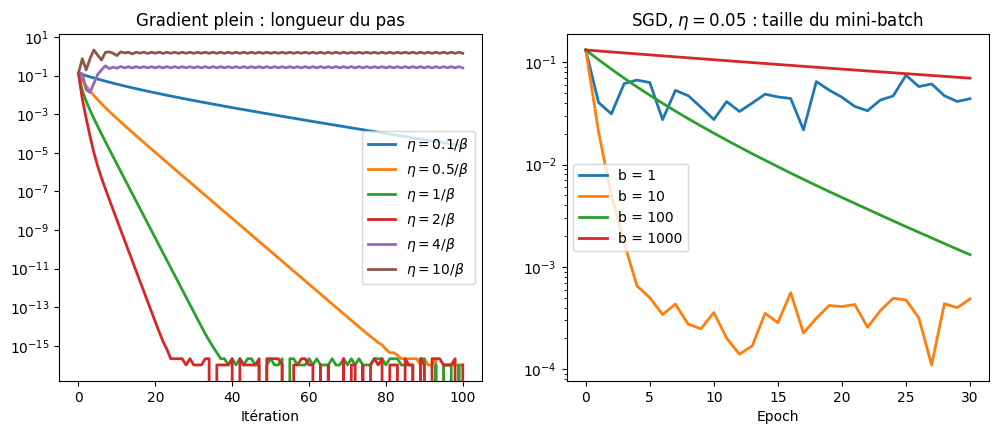

In [5]:
m, n = 1000, 20
A = rng.normal(0, 1, (m, n)); y = (rng.random(m) < sigmoid(A @ rng.normal(0, 1, n) / np.sqrt(n))).astype(float)
beta = smoothness(A); gradient = lambda x: logistic_gradient(A, y, x)
f_opt = logistic(A, y, gradient_descent(np.zeros(n), [1 / beta] * 3000, gradient)[-1])
gap = lambda xs: [logistic(A, y, x) - f_opt + 1e-16 for x in xs]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for c in [0.1, 0.5, 1, 2, 4, 10]:
    error_plot(gap(gradient_descent(np.zeros(n), [c / beta] * 100, gradient)), ax[0], label=f'$\\eta={c}/\\beta$')
ax[0].set_title('Gradient plein : longueur du pas'); ax[0].legend()
for b in [1, 10, 100, m]:
    error_plot(gap(sgd(A, y, np.zeros(n), step=0.05, batch_size=b, epochs=30)), ax[1], label=f'b = {b}')
ax[1].set_xlabel('Epoch'); ax[1].set_title('SGD, $\\eta=0.05$ : taille du mini-batch'); ax[1].legend(); save('pas_minilot'); plt.show()

* **Pas** : décroissance garantie pour $\eta<2/\beta$ ; $\eta$ trop petit est lent ; au-delà de $2/\beta$ la
  décroissance n'est plus garantie et, pour $\eta$ grand, la méthode oscille.
* **Mini-batch** : une epoch coûte $m$ gradients individuels quelle que soit $b$, mais fait $m/b$ mises à jour.
  Les petits mini-batchs progressent vite puis plafonnent à un niveau de bruit $\propto\eta/b$ (variance du gradient
  $\propto 1/b$) ; les grands mini-batchs sont précis mais font peu de mises à jour ($b=m$ : gradient plein).

## 3. Les 6 hypothèses de la régression logistique (Kenneth Leung)

Leung ajuste le modèle avec `statsmodels`. Ici, **notre descente de gradient** donne l'estimateur $\hat x$
(variables standardisées, ce qui ne change ni les prédictions ni les tests), et toutes les quantités statistiques
viennent de la Hessienne $H=A^\top WA$ :
* $p$-valeurs de Wald : $\widehat{\mathrm{Cov}}(\hat x)=H^{-1}$, $z_j=\hat x_j/\sqrt{(H^{-1})_{jj}}$ ;
* levier $h_i=\big(W^{1/2}AH^{-1}A^\top W^{1/2}\big)_{ii}$, résidu de Pearson $r_i=(y_i-p_i)/\sqrt{p_i(1-p_i)}$,
  distance de Cook $D_i=\frac{r_i^2}{k}\frac{h_i}{(1-h_i)^2}$ ($k$ = nombre de paramètres) ;
* VIF$_j=\big[R^{-1}\big]_{jj}$ où $R$ est la matrice de corrélation des variables explicatives.

In [6]:
def fit_gd(X, y, tol=1e-6, max_iter=200000):
    # Régression logistique (avec intercept) par descente de gradient, eta = 1/beta, variables standardisées.
    Z = (X - X.mean(0)) / X.std(0)
    A = np.column_stack([np.ones(len(Z)), Z]); beta = smoothness(A); x = np.zeros(A.shape[1])
    for it in range(max_iter):
        g = logistic_gradient(A, y, x)
        if np.linalg.norm(g) < tol: break
        x = x - g / beta
    return A, x, it

def wald_table(A, y, x, names):
    p = sigmoid(A @ x); H = (A.T * (p * (1 - p))) @ A
    se = np.sqrt(np.diag(np.linalg.inv(H)))
    return pd.DataFrame({'coef (std.)': x, 'z': x / se, 'p-valeur': 2 * norm.sf(np.abs(x / se))},
                        index=['const'] + names).round(4)

def check_assumptions(X, y, continuous, name, tag):
    X = X.astype(float); y = y.astype(float); names = list(X.columns)
    A, x, it = fit_gd(X.values, y)
    print(f'===== {name} : m = {len(y)}, {len(names)} variables, GD convergé en {it} itérations')
    print(wald_table(A, y, x, names), '\n')

    # 1. Variable réponse binaire
    print('1) Modalités de la réponse :', dict(pd.Series(y).value_counts()))

    # 2. Linéarité du logit : Box-Tidwell (termes x ln x, sur les valeurs > 0)
    keep = (X[continuous] > 0).all(axis=1)
    Xbt = X[keep].copy()
    for c in continuous:
        Xbt[f'{c}:log_{c}'] = Xbt[c] * np.log(Xbt[c])
    bt_cols = continuous + [f'{c}:log_{c}' for c in continuous]
    Abt, xbt, _ = fit_gd(Xbt[bt_cols].values, y[keep.values])
    print('2) Box-Tidwell (p < 0,05 sur un terme x ln x => non-linéarité) :')
    print(wald_table(Abt, y[keep.values], xbt, bt_cols).iloc[1 + len(continuous):], '\n')
    p = sigmoid(A @ x); logit = A @ x
    fig, ax = plt.subplots(1, len(continuous) + 2, figsize=(5 * (len(continuous) + 2), 4))
    for a, c in zip(ax, continuous):
        a.scatter(X[c], logit, s=8); a.set_xlabel(c); a.set_ylabel('log-odds prédits')

    # 3. Observations influentes : distance de Cook > 4/m et |résidu standardisé| > 3
    W = p * (1 - p); k = A.shape[1]
    B = A * np.sqrt(W)[:, None]
    h = np.einsum('ij,ij->i', B @ np.linalg.inv(B.T @ B), B)
    r = (y - p) / np.sqrt(W)
    cook = r ** 2 / k * h / (1 - h) ** 2
    std_r = np.abs((r - r.mean()) / r.std())
    thr = 4 / len(y)
    print(f'3) Cook > 4/m = {thr:.4f} : {100 * np.mean(cook > thr):.1f} % ; '
          f'influents ET |résidu std| > 3 : {100 * np.mean((cook > thr) & (std_r > 3)):.1f} %')
    a = ax[len(continuous)]; a.stem(cook, markerfmt=' '); a.axhline(thr, color='r', ls='--')
    a.set_title('Distance de Cook'); a.set_xlabel('Indice')

    # 4. Multicolinéarité : VIF (> 5 problématique)
    vif = np.diag(np.linalg.inv(np.corrcoef(X.values, rowvar=False)))
    print('4) VIF :', dict(zip(names, vif.round(2))))

    # 5. Indépendance : résidus de déviance en fonction de l'indice
    dev = np.sign(y - p) * np.sqrt(-2 * (y * np.log(p) + (1 - y) * np.log(1 - p)))
    a = ax[-1]; a.plot((dev - dev.mean()) / dev.std(), lw=.7); a.axhline(0, color='r', ls='--')
    a.set_title('Résidus de déviance (standardisés)'); a.set_xlabel('Indice')
    plt.tight_layout(); save('diag_' + tag); plt.show()

    # 6. Taille d'échantillon : >= 500 observations et >= 10 cas de la classe rare par variable
    epv = min(y.sum(), len(y) - y.sum()) / len(names)
    print(f'6) m = {len(y)} ; événements par variable = {epv:.1f} (règle : >= 10)')
    for c in names:
        if set(X[c].unique()) <= {0., 1.}:
            print(f'   {c}: {int(X[c].sum())} uns / {int((1 - X[c]).sum())} zéros')

### 3.1 Titanic
Prétraitement identique à Leung : variable `TravelAlone`, indicatrices (première modalité supprimée pour éviter la
colinéarité), âge manquant remplacé par la médiane.

===== Titanic : m = 891, 8 variables, GD convergé en 158 itérations
             coef (std.)        z  p-valeur
const            -0.6561  -7.2102    0.0000
Age              -0.4336  -4.3965    0.0000
Fare              0.0181   0.1642    0.8696
TravelAlone       0.0340   0.3544    0.7230
Pclass_2         -0.3807  -3.2357    0.0012
Pclass_3         -1.1309  -7.8694    0.0000
Embarked_Q       -0.0095  -0.0906    0.9278
Embarked_S       -0.2480  -2.3532    0.0186
Sex_male         -1.2382 -13.2056    0.0000 

1) Modalités de la réponse : {0.0: 549, 1.0: 342}
2) Box-Tidwell (p < 0,05 sur un terme x ln x => non-linéarité) :
               coef (std.)       z  p-valeur
Age:log_Age         1.2446  1.6409    0.1008
Fare:log_Fare      -3.3685 -5.2506    0.0000 

3) Cook > 4/m = 0.0045 : 6.1 % ; influents ET |résidu std| > 3 : 1.3 %
4) VIF : {'Age': 1.21, 'Fare': 1.69, 'TravelAlone': 1.22, 'Pclass_2': 2.07, 'Pclass_3': 2.7, 'Embarked_Q': 1.49, 'Embarked_S': 1.48, 'Sex_male': 1.15}


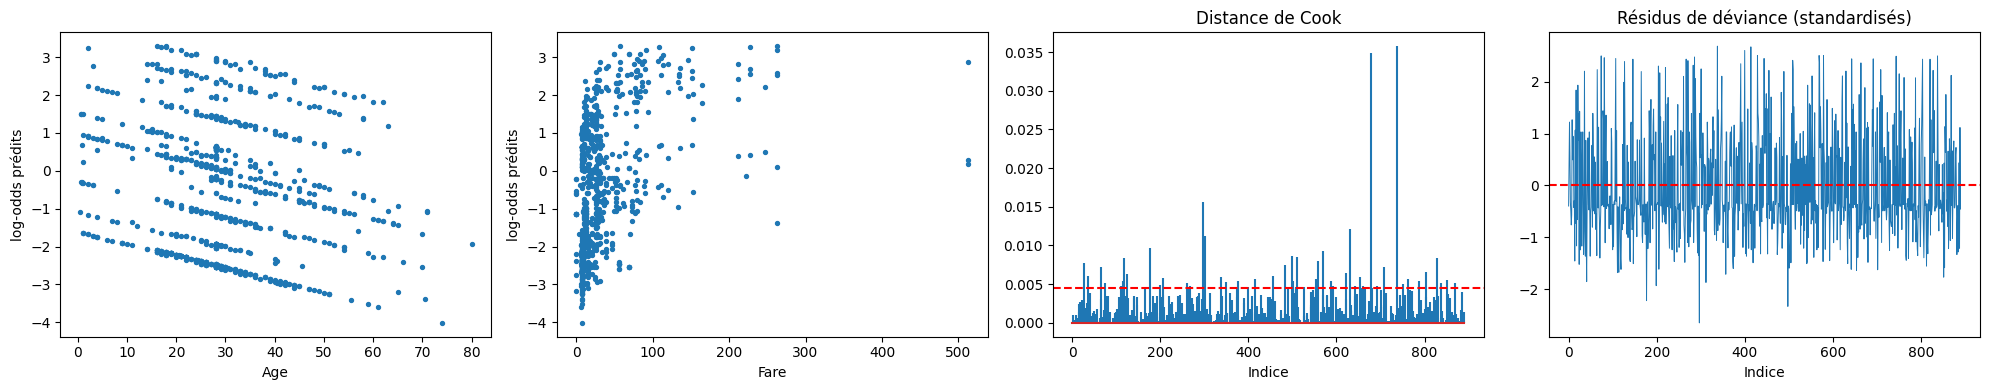

6) m = 891 ; événements par variable = 42.8 (règle : >= 10)
   TravelAlone: 537 uns / 354 zéros
   Pclass_2: 184 uns / 707 zéros
   Pclass_3: 491 uns / 400 zéros
   Embarked_Q: 77 uns / 814 zéros
   Embarked_S: 644 uns / 247 zéros
   Sex_male: 577 uns / 314 zéros


In [7]:
df = pd.read_csv('../Kenneth-Leung/data/train.csv')
df['TravelAlone'] = np.where(df.SibSp + df.Parch > 0, 0, 1)
df = df.drop(columns=['SibSp', 'Parch', 'PassengerId', 'Name', 'Ticket', 'Cabin'])
df = pd.get_dummies(df, columns=['Pclass', 'Embarked', 'Sex'], drop_first=True, dtype=float)
df['Age'] = df['Age'].fillna(df['Age'].median())
check_assumptions(df.drop(columns='Survived'), df['Survived'].values, ['Age', 'Fare'], 'Titanic', 'titanic')

### 3.2 Irish Educational Transitions (Greaney & Kelleghan, 1984)
500 élèves irlandais de 11 ans suivis à partir de 1967 ([OpenML 451](https://www.openml.org/d/451)). Réponse :
`Leaving_Certificate` (l'équivalent du baccalauréat français) passé ou non. Variables : sexe, score au test de raisonnement verbal de Drumcondra (`DVRT`),
prestige de la profession du père (`Prestige_score`), type d'école. Comme dans l'analyse de Raftery & Hout, on retire
les élèves ayant quitté l'école après le primaire (qui ne passent jamais le Leaving Certificate : séparation parfaite)
et les valeurs manquantes (441 élèves), ainsi que `Educational_level` (déterminé après coup, il contient la réponse).

===== Irish Educational Transitions : m = 441, 4 variables, GD convergé en 76 itérations
                        coef (std.)       z  p-valeur
const                       -0.3882 -2.6453    0.0082
DVRT                         0.5916  4.3605    0.0000
Prestige_score               0.3903  3.0387    0.0024
Sex_male                     0.0025  0.0195    0.9844
Type_school_vocational      -1.4361 -7.4796    0.0000 

1) Modalités de la réponse : {0.0: 230, 1.0: 211}
2) Box-Tidwell (p < 0,05 sur un terme x ln x => non-linéarité) :
                                   coef (std.)       z  p-valeur
DVRT:log_DVRT                           6.8534  0.9325    0.3511
Prestige_score:log_Prestige_score      -1.2802 -0.5333    0.5938 

3) Cook > 4/m = 0.0091 : 4.8 % ; influents ET |résidu std| > 3 : 1.6 %
4) VIF : {'DVRT': 1.17, 'Prestige_score': 1.12, 'Sex_male': 1.09, 'Type_school_vocational': 1.24}


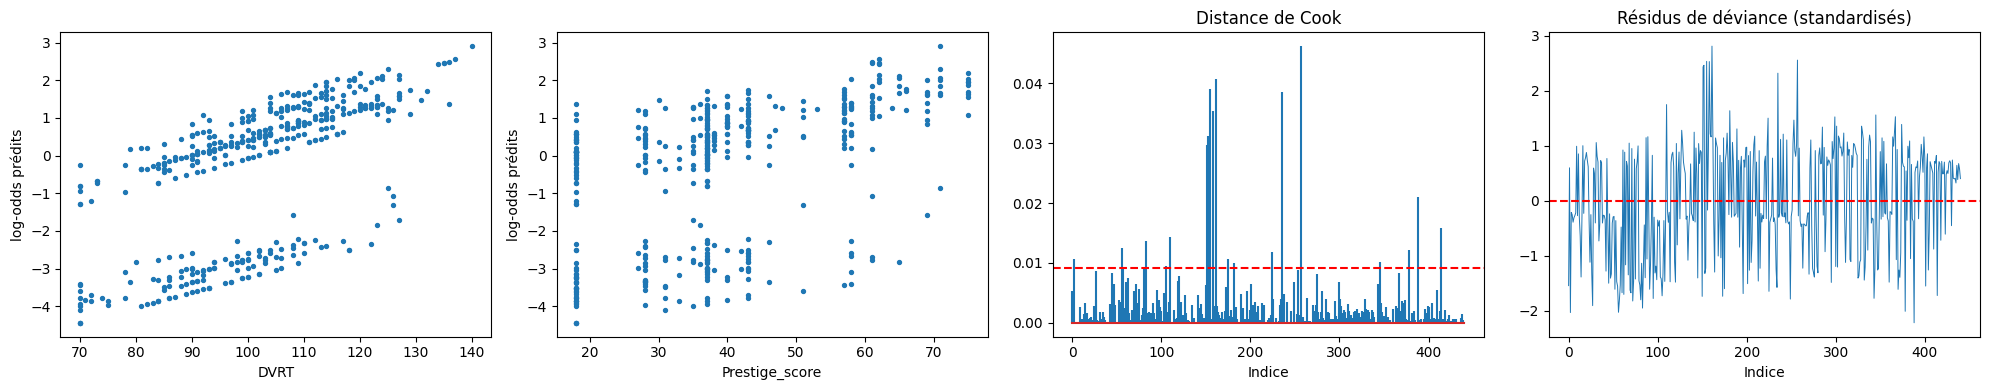

6) m = 441 ; événements par variable = 52.8 (règle : >= 10)
   Sex_male: 217 uns / 224 zéros
   Type_school_vocational: 130 uns / 311 zéros


In [8]:
from sklearn.datasets import fetch_openml
if os.path.exists('data/irish.csv'):
    ir = pd.read_csv('data/irish.csv')
else:
    ir = fetch_openml(data_id=451, as_frame=True).frame
    os.makedirs('data', exist_ok=True); ir.to_csv('data/irish.csv', index=False)
ir = ir.astype({c: str for c in ['Sex', 'Type_school', 'Leaving_Certificate']})
ir = ir[ir.Type_school != 'primary_terminal_leaver'].drop(columns='Educational_level').dropna()
y_ir = (ir.pop('Leaving_Certificate') == 'taken').values
X_ir = pd.get_dummies(ir, columns=['Sex', 'Type_school'], drop_first=True, dtype=float)
check_assumptions(X_ir, y_ir, ['DVRT', 'Prestige_score'], 'Irish Educational Transitions', 'irlande')

## Conclusion
* Avec $\eta=1/\beta$, le gradient converge linéairement dans le cas $m\ge n$. Dans le cas séparable ($m<n$), il n'y a pas de minimiseur ($\|x_k\|\to\infty$) ; la pénalité $\ell_2$ rétablit un minimiseur unique et une convergence linéaire.
* Pas : $1/\beta$ et $2/\beta$ convergent en quelques dizaines d'itérations, $0{,}1/\beta$ est lent, $4/\beta$ et $10/\beta$ oscillent sans converger.
* Mini-batch ($\eta=0{,}05$) : $b=1$ reste très bruité, $b=10$ descend le plus vite puis plafonne vers $10^{-4}$, $b=100$ converge régulièrement, $b=m$ progresse lentement (une mise à jour par epoch).
* Titanic : on retrouve les résultats de Leung ; seule la linéarité du logit pour `Fare` est violée (Box-Tidwell, $p<0{,}001$).
* Irlande : DVRT, prestige et type d'école sont significatifs, pas le sexe ; les hypothèses sont vérifiées, avec $m=441<500$ et un fichier dont l'ordre n'est pas aléatoire (légère structure des résidus selon l'indice).